# DIGITAL SIGNAL PROCESSING LABORATORY

## WEEK_01 — LAB 0
### Setting Up the DSP Laboratory

**Name:** HAULE, FELIX DITRICK

**Registration Number:** 240242404549

**Module Code:** COU 07506

**Laboratory:** Week 1

**Date:** 24 November 2026

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP environment is ready!")

DSP environment is ready!



## Pre-Laboratory Exercise

### Question
List three devices used in everyday life that apply Digital Signal Processing (DSP), and identify one signal processed by each device.

### Answer

1. **Smartphone:** Processes speech signals during phone calls to improve voice quality and reduce background noise.
2. **Digital television:** Processes audio and video signals to provide clear sound and pictures.
3. **Bluetooth speaker:** Processes digital audio signals to reproduce sound through its speakers.

These devices use DSP techniques to manipulate, improve, transmit, or reproduce signals.



## Task 1.1 — Generation of Basic Discrete-Time Signals

### Objective
Generate and visualize the unit impulse, unit step, ramp, and exponential signals using Python.

The signals are defined as follows:

- Unit impulse: δ(n) = 1 when n = 0, otherwise 0.
- Unit step: u(n) = 1 when n ≥ 0, otherwise 0.
- Ramp: r(n) = n u(n).
- Exponential: x(n) = (0.8)^n u(n).

### Python Implementation


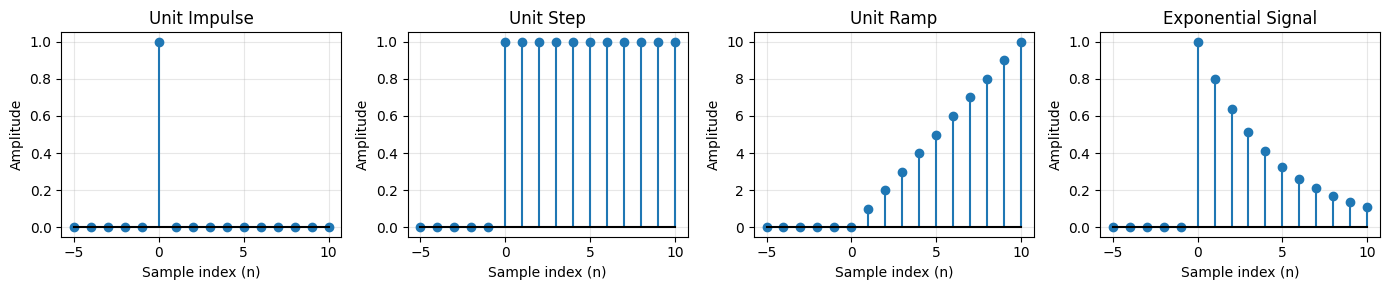

In [18]:

n = np.arange(-5, 11)

# Generate the signals
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = (0.8 ** n) * step

# Plot the signals
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

signals = [delta, step, ramp, expo]
titles = [
    "Unit Impulse",
    "Unit Step",
    "Unit Ramp",
    "Exponential Signal"
]

for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Task 1.2 — Exponential and Cosine Signals

### Part A: Exponential Signals

Generate and compare exponential signals using the values:

a = 0.5, a = -0.8, and a = 1.1.

The general expression is:

x(n) = aⁿu(n)

### Part B: Cosine Signals

Generate and compare:

- x₁(n) = cos(2πn/8)
- x₂(n) = cos(2πn/7.5)

Use sample indices from n = 0 to n = 40.


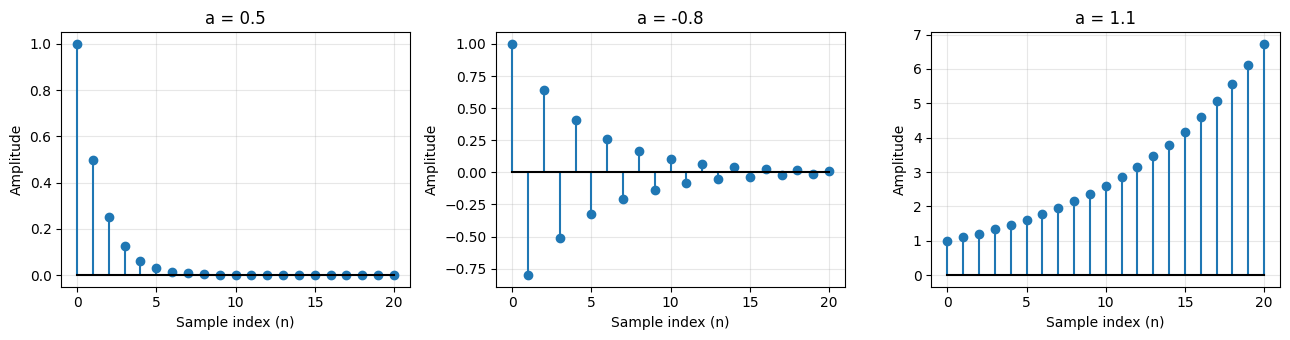

In [19]:

n = np.arange(0, 21)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = a ** n

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

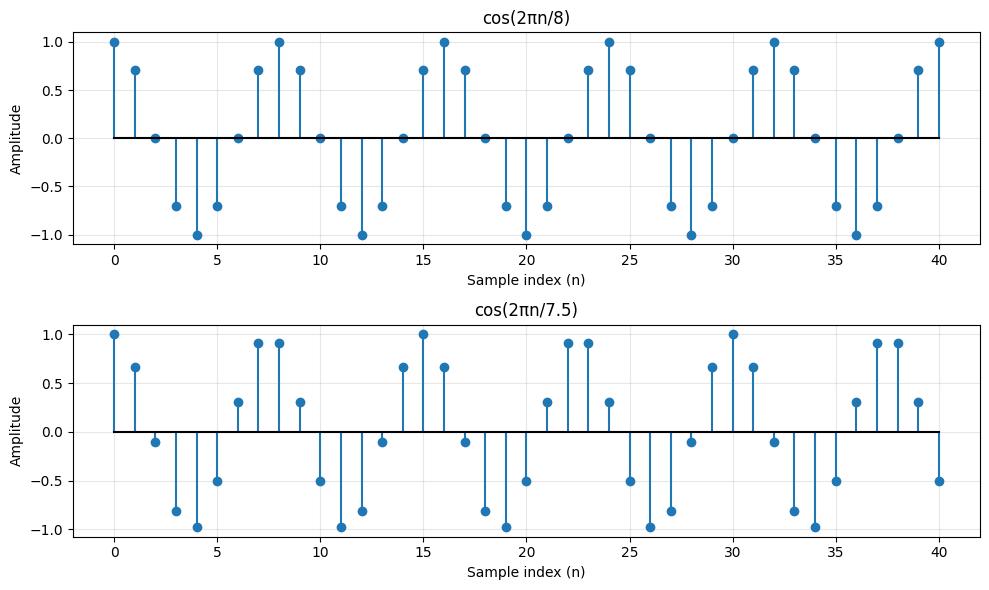

In [20]:

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("Sample index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Discussion: Periodicity of the Cosine Signals

A discrete-time cosine signal is periodic if there is a positive integer N such that:

x(n + N) = x(n)

For the first signal:

x₁(n) = cos(2πn/8)

Its fundamental period is N = 8 samples.

For the second signal:

x₂(n) = cos(2πn/7.5)

Since 1/7.5 = 2/15, its fundamental period is N = 15 samples.

**Conclusion:**

Both signals are periodic. The first signal repeats after 8 samples, while the second repeats after 15 samples. Therefore, both repeat exactly, but at different intervals.



## Task 1.3 — Recording and Processing an Audio Signal

### Objective

Record a voice signal, load the WAV audio file into Python, convert it to mono if necessary, normalize the amplitude, and visualize the waveform.

The audio recording is stored locally as `my_voice.wav` in the same directory as this notebook.

### Python Implementation


Sampling rate: 44100 Hz
Duration: 4.59 seconds
Number of samples: 202419


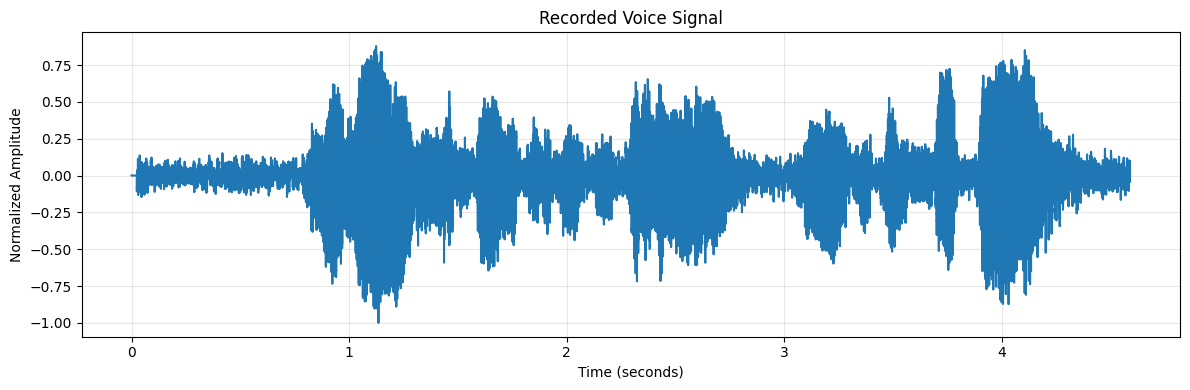

In [21]:

import os

fname = "my_voice.wav"

# Check that the recording is available
if not os.path.exists(fname):
    raise FileNotFoundError(
        "my_voice.wav was not found. "
        "Place your recording in the same folder as this notebook."
    )

# Read the WAV file
fs, x = wavfile.read(fname)

# Convert samples to floating-point values
x = x.astype(np.float64)

# Convert stereo audio to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize the signal
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

# Generate time axis
t = np.arange(len(x)) / fs

# Display audio information
print(f"Sampling rate: {fs} Hz")
print(f"Duration: {len(x) / fs:.2f} seconds")
print(f"Number of samples: {len(x)}")

# Plot waveform
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.title("Recorded Voice Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

from IPython.display import Audio, display

display(Audio(x, rate=fs))


### Discussion

The recorded audio was successfully loaded and processed using SciPy.

The sampling rate represents the number of samples recorded per second. The duration is calculated by dividing the total number of samples by the sampling rate.

For stereo recordings, the left and right channels were averaged to produce a mono signal. The signal was then normalized so that its maximum absolute amplitude was 1, provided the recording was not silent.

The waveform plot shows how the audio signal amplitude changes over time.



## Laboratory Analysis Questions

### Question 1
How many samples are required to record a one-minute mono audio signal at a sampling rate of 44,100 Hz?

**Answer:**

The number of samples is calculated using:

Number of samples = Sampling rate × Duration

= 44,100 × 60

= **2,646,000 samples**

Therefore, a one-minute mono recording at 44,100 Hz contains 2,646,000 samples.

### Question 2
Why is a stem plot appropriate for displaying discrete-time signals?

**Answer:**

A stem plot is appropriate because discrete-time signals consist of individual samples at specific integer time indices. It displays each sample separately, making it easy to identify the amplitude and position of every sample.

### Question 3
Why is an exponential signal with a = 1.1 not BIBO stable?

**Answer:**

For a discrete-time system to be BIBO stable, its impulse response must be absolutely summable.

For the exponential signal:

h(n) = (1.1)ⁿu(n)

The signal increases as n increases because 1.1 is greater than 1. Therefore, its absolute sum does not converge to a finite value.

Consequently, the system is not BIBO stable.
